In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / "outputs" / "experiment_config.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("找不到项目根")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
print("ROOT =", ROOT)

FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("FIG =", FIG)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open(ROOT / "outputs" / "experiment_config.json", encoding="utf-8") as f:
    config = json.load(f)

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"

ROOT = d:\课程\5001\group\msbd5001-olist
FIG = d:\课程\5001\group\msbd5001-olist\outputs\figures


Matplotlib is building the font cache; this may take a moment.


AP 对比柱状图：E0/E1/E2/E3 full + 调参后。

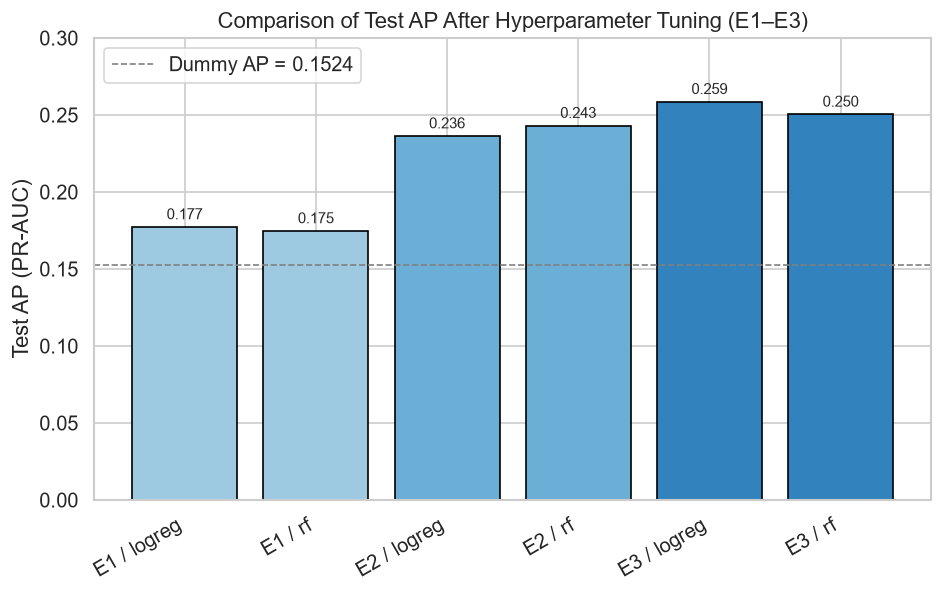

saved fig_ap_comparison.png


In [4]:
df = pd.read_csv(ROOT / "outputs" / "metrics.csv")

# 取调参后主结果 + E0
main = df[df["notes"].str.contains("final | tuned", na=False)].copy()
e0 = df[df["notes"].eq("E0 baseline")].copy()
plot_df = pd.concat([e0, main], ignore_index=True)

# 只保留 LogReg 和 RF 中 AP 最高的那一行
plot_df["exp_label"] = plot_df["experiment"] + " / " + plot_df["model"]

order = ["E1 / logreg", "E1 / rf", "E2 / logreg", "E2 / rf",
         "E3 / logreg", "E3 / rf"]
plot_df = plot_df.set_index("exp_label").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#9ecae1", "#9ecae1", "#6baed6", "#6baed6", "#3182bd", "#3182bd"]
bars = ax.bar(plot_df["exp_label"], plot_df["AP"], color=colors, edgecolor="black")
for bar, ap in zip(bars, plot_df["AP"]):
    ax.text(bar.get_x() + bar.get_width()/2, ap + 0.003,
            f"{ap:.3f}", ha="center", va="bottom", fontsize=9)
ax.axhline(0.1524, color="gray", linestyle="--", linewidth=1,
           label="Dummy AP = 0.1524")
ax.set_ylabel("Test AP (PR-AUC)")
ax.set_title("Comparison of Test AP After Hyperparameter Tuning (E1–E3)")
ax.set_ylim(0, 0.30)
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.savefig(FIG / "fig_ap_comparison.png")
plt.show()
print("saved fig_ap_comparison.png")

消融对比柱状图：四个消融组 vs E3 full，两个模型并排。

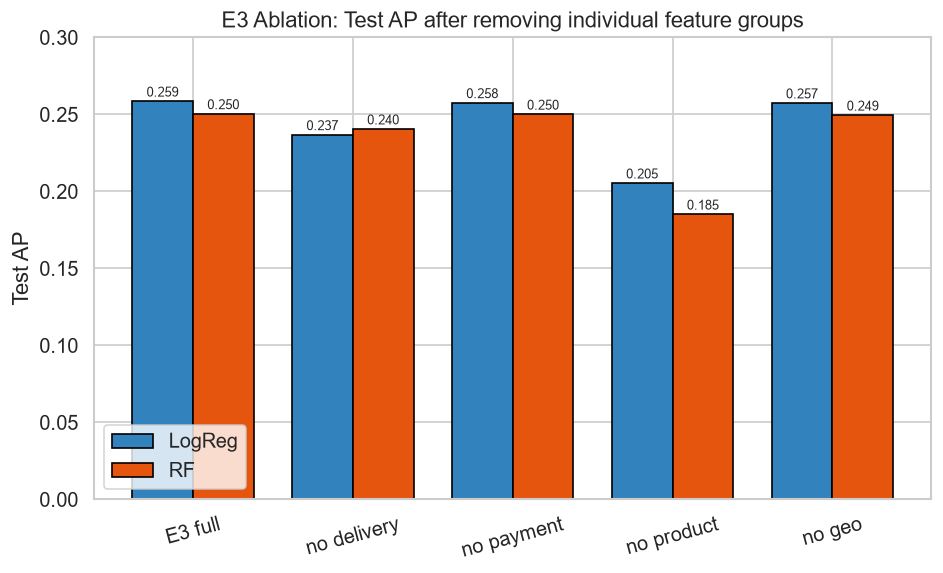

saved fig_ablation.png


In [5]:
abl = df[df["notes"].str.contains("ablation", na=False)].copy()

# 消融表：variant × model 的 test AP
pivot = abl.pivot_table(index="experiment", columns="model",
                        values="AP", aggfunc="max")

# 加上 E3 full 作为基准
e3_full = df[df["notes"].str.contains("final | tuned", na=False)]
e3_full = e3_full[e3_full["experiment"].eq("E3")].set_index("model")["AP"]
pivot.loc["E3 (full)"] = e3_full

# 排序
order = ["E3 (full)", "E3_no_delivery", "E3_no_payment",
         "E3_no_product", "E3_no_geo"]
pivot = pivot.loc[order]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(pivot))
width = 0.38
ax.bar(x - width/2, pivot["logreg"], width, label="LogReg",
       color="#3182bd", edgecolor="black")
ax.bar(x + width/2, pivot["rf"], width, label="RF",
       color="#e6550d", edgecolor="black")

for i, v in enumerate(pivot["logreg"]):
    ax.text(i - width/2, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
for i, v in enumerate(pivot["rf"]):
    ax.text(i + width/2, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(["E3 full", "no delivery", "no payment",
                    "no product", "no geo"], rotation=15)
ax.set_ylabel("Test AP")
ax.set_title("E3 Ablation: Test AP after removing individual feature groups")
ax.set_ylim(0, 0.30)
ax.legend()
plt.savefig(FIG / "fig_ablation.png")
plt.show()
print("saved fig_ablation.png")

PR 曲线（E1/E2/E3 LogReg 同图）

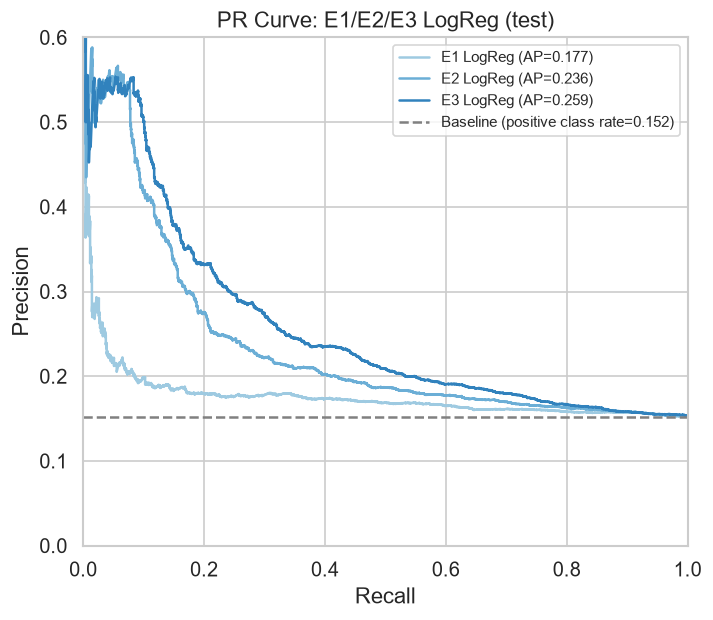

saved fig_pr_curve.png


In [6]:
from sklearn.metrics import precision_recall_curve, average_precision_score

pred = pd.read_csv(ROOT / "outputs" / "test_predictions.csv")

def get_pred(exp, model, tag_contains):
    sub = pred[(pred["experiment"].eq(exp)) &
               (pred["model"].eq(model)) &
               (pred["tag"].str.contains(tag_contains, na=False))]
    sub = sub.sort_values("order_id").reset_index(drop=True)
    return sub["y_true"].values, sub["y_prob"].values

fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = {"E1": "#9ecae1", "E2": "#6baed6", "E3": "#3182bd"}
for stage in ["E1", "E2", "E3"]:
    y, p = get_pred(stage, "logreg", "final | tuned")
    prec, rec, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    ax.plot(rec, prec, color=colors[stage],
            label=f"{stage} LogReg (AP={ap:.3f})")

ax.axhline(y.mean(), color="gray", linestyle="--",
           label=f"Baseline (positive class rate={y.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("PR Curve: E1/E2/E3 LogReg (test)")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.6)
plt.savefig(FIG / "fig_pr_curve.png")
plt.show()
print("saved fig_pr_curve.png")

阈值-F1 曲线（E3 LogReg）

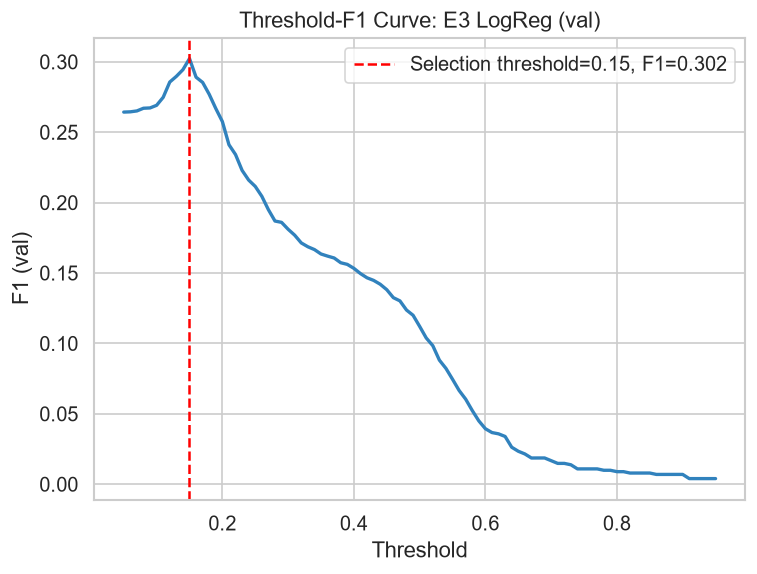

saved fig_threshold_f1.png


In [7]:
from sklearn.metrics import f1_score

y_va, p_va = get_pred("E3", "logreg", "final | tuned")

thresholds = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_va, (p_va >= t).astype(int), pos_label=1)
       for t in thresholds]

# 选出的最佳阈值
from train_evaluate import choose_threshold
best_t, best_f1 = choose_threshold(y_va, p_va, config["threshold_grid"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(thresholds, f1s, color="#3182bd", linewidth=2)
ax.axvline(best_t, color="red", linestyle="--",
           label=f"Selection threshold={best_t:.2f}, F1={best_f1:.3f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("F1 (val)")
ax.set_title("Threshold-F1 Curve: E3 LogReg (val)")
ax.legend()
plt.savefig(FIG / "fig_threshold_f1.png")
plt.show()
print("saved fig_threshold_f1.png")

混淆矩阵（E3 LogReg test）

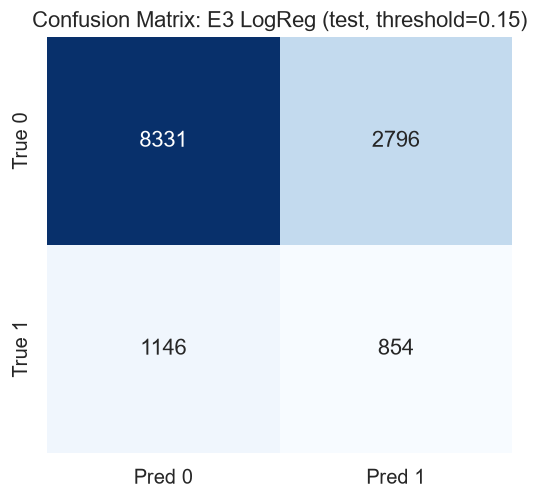

saved fig_confusion_matrix.png
TN=8331, FP=2796, FN=1146, TP=854
precision=0.2340, recall=0.4270, F1=0.3023


In [8]:
from sklearn.metrics import confusion_matrix

y_te, p_te = get_pred("E3", "logreg", "final | tuned")

# 用 val 上选出的阈值
y_pred_te = (p_te >= best_t).astype(int)

cm = confusion_matrix(y_te, y_pred_te, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred 0", "Pred 1"],
            yticklabels=["True 0", "True 1"], ax=ax)
ax.set_title(f"Confusion Matrix: E3 LogReg (test, threshold={best_t:.2f})")
plt.savefig(FIG / "fig_confusion_matrix.png")
plt.show()
print("saved fig_confusion_matrix.png")

# 顺便打印 precision / recall / F1
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"precision={tp/(tp+fp):.4f}, recall={tp/(tp+fn):.4f}, F1={2*tp/(2*tp+fp+fn):.4f}")

特征重要性（RF Top 20）

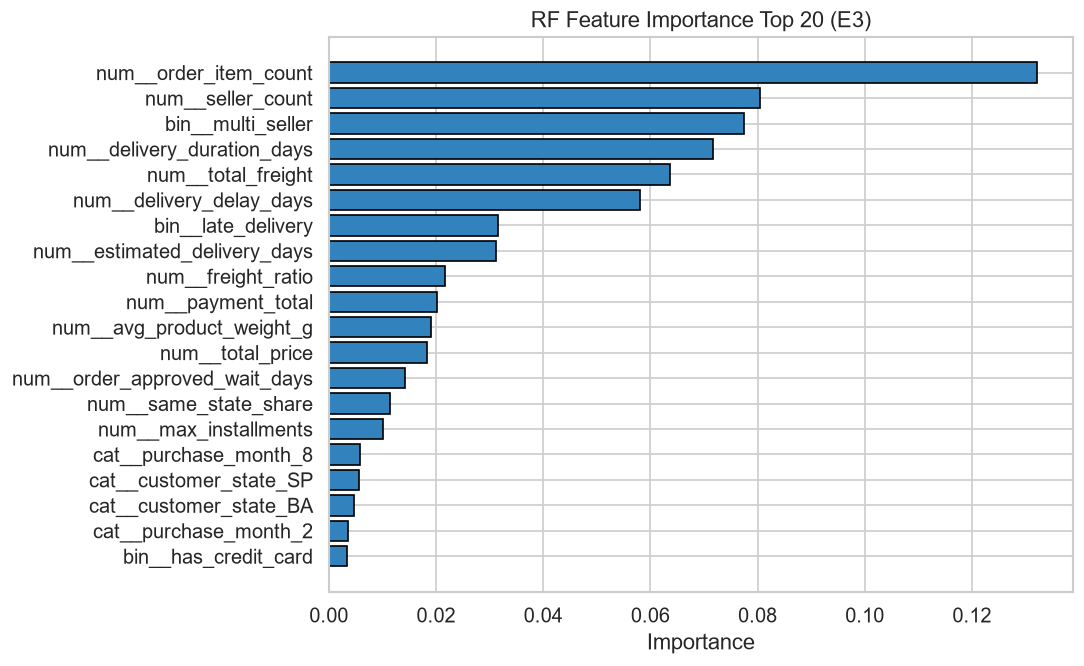

saved fig_feature_importance.png


In [9]:
from train_evaluate import (
    load_stage, build_masks, make_preprocessor, make_model,
    split_feature_columns, SEED,
)

# 用 E3 数据训练一个 RF，取 feature_importances_
X, y, split = load_stage("E3")
masks = build_masks(split)
X_tr = X.loc[masks["train"]]
y_tr = y.loc[masks["train"]]

pre = make_preprocessor("E3", "rf")
X_tr_t = pre.fit_transform(X_tr)

rf = make_model("rf", class_weight=None,
                params={"n_estimators": 300, "max_depth": 10,
                        "min_samples_leaf": 1})
rf.fit(X_tr_t, y_tr)

# 把 one-hot 后的维度映射回原列名
feature_names = pre.get_feature_names_out()
importances = rf.feature_importances_

imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
imp_df = imp_df.sort_values("importance", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp_df["feature"][::-1], imp_df["importance"][::-1],
        color="#3182bd", edgecolor="black")
ax.set_xlabel("Importance")
ax.set_title("RF Feature Importance Top 20 (E3)")
plt.savefig(FIG / "fig_feature_importance.png")
plt.show()
print("saved fig_feature_importance.png")

bootstrap 分布图

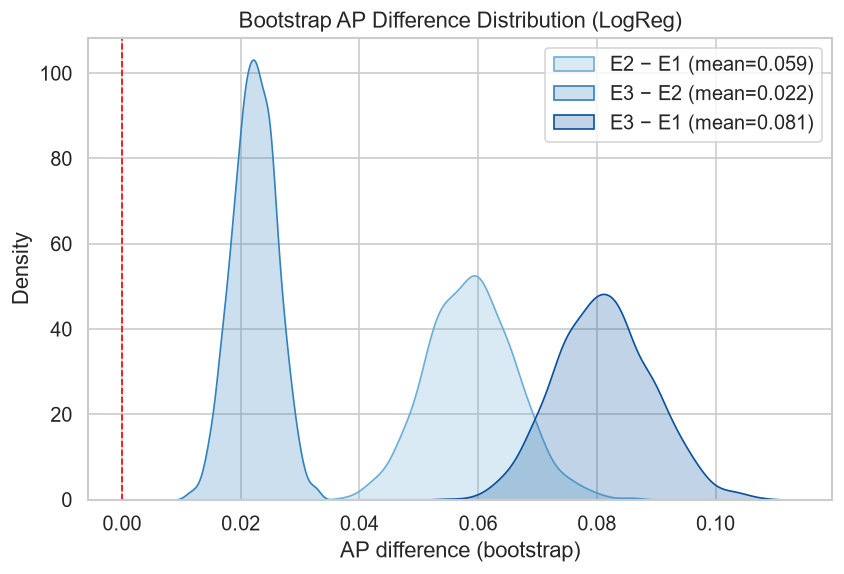

saved fig_bootstrap.png


In [10]:
import importlib
import train_evaluate
importlib.reload(train_evaluate)
from train_evaluate import paired_bootstrap
from sklearn.metrics import average_precision_score

y1, p_e1 = get_pred("E1", "logreg", "final | tuned")
_, p_e2 = get_pred("E2", "logreg", "final | tuned")
_, p_e3 = get_pred("E3", "logreg", "final | tuned")

# 自定义 bootstrap 保留全部差值
def bootstrap_diffs(y, p_a, p_b, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    diffs = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, len(y), len(y))
        diffs[i] = (average_precision_score(y[idx], p_a[idx])
                    - average_precision_score(y[idx], p_b[idx]))
    return diffs

d21 = bootstrap_diffs(y1, p_e2, p_e1)
d32 = bootstrap_diffs(y1, p_e3, p_e2)
d31 = bootstrap_diffs(y1, p_e3, p_e1)

fig, ax = plt.subplots(figsize=(8, 5))
for d, label, color in [
    (d21, "E2 − E1", "#6baed6"),
    (d32, "E3 − E2", "#3182bd"),
    (d31, "E3 − E1", "#08519c"),
]:
    sns.kdeplot(d, ax=ax, label=f"{label} (mean={d.mean():.3f})",
                color=color, fill=True, alpha=0.25)

ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("AP difference (bootstrap)")
ax.set_title("Bootstrap AP Difference Distribution (LogReg)")
ax.legend()
plt.savefig(FIG / "fig_bootstrap.png")
plt.show()
print("saved fig_bootstrap.png")

In [11]:
import os
for f in sorted(os.listdir(FIG)):
    print(f, os.path.getsize(FIG / f), "bytes")

fig_ablation.png 38851 bytes
fig_ap_comparison.png 42013 bytes
fig_bootstrap.png 57700 bytes
fig_class_distribution.png 21215 bytes
fig_confusion_matrix.png 18338 bytes
fig_feature_histograms.png 37403 bytes
fig_feature_importance.png 72519 bytes
fig_lowrate_drift.png 69426 bytes
fig_missingness.png 37235 bytes
fig_pr_curve.png 53082 bytes
fig_split_timeline.png 49141 bytes
fig_threshold_f1.png 39025 bytes
